 Import Pandas and load the CSV

In [4]:
import pandas as pd
import re

In [5]:
df = pd.read_csv("anime (1).csv")

In [6]:
df.head()

,Rank,Title,Score
0,1,Fullmetal Alchemist: BrotherhoodTV (64 eps)Apr...,9.10
1,2,"Steins;GateTV (24 eps)Apr 2011 - Sep 20112,473...",9.07
2,3,Bleach: Sennen Kessen-henTV (13 eps)Oct 2022 -...,9.06
3,4,"Gintama°TV (51 eps)Apr 2015 - Mar 2016605,113 ...",9.06
4,5,Shingeki no Kyojin Season 3 Part 2TV (10 eps)A...,9.05


In [7]:
print("Dataset shape:", df.shape)

Dataset shape: (50, 3)


In [8]:
print("Columns:", df.columns.tolist())

Columns: ['Rank', 'Title', 'Score']


1.Make a new column for episode count

In [9]:

def extract_episodes(txt):
    check = False
    data = ""
    for i in txt:
        if i == ")":
            check = False
            return data
        if check == True:
            data = data + i
        if i == "(":
            check = True


df["Episodes"] = df["Title"].apply(extract_episodes)
df["Episodes"] = df["Episodes"].str.replace(" eps", "")


df.head(2)

,Rank,Title,Score,Episodes
0,1,Fullmetal Alchemist: BrotherhoodTV (64 eps)Apr...,9.10,64
1,2,"Steins;GateTV (24 eps)Apr 2011 - Sep 20112,473...",9.07,24


2.Make a new column for time stamp

In [10]:
import re

def extract_timestamp(txt):
    # Regex diye date pattern (Month Year - Month Year) khuje ber korbe
    date_match = re.search(r'([A-Z][a-z]{2}\s+\d{4}\s*-\s*[A-Z][a-z]{2}\s+\d{4})', txt)
    if date_match:
        return date_match.group(1)
    return None

In [11]:
df["Time Stamp"] = df["Title"].apply(extract_timestamp)

In [12]:
df.head(2)

,Rank,Title,Score,Episodes,Time Stamp
0,1,Fullmetal Alchemist: BrotherhoodTV (64 eps)Apr...,9.10,64,Apr 2009 - Jul 2010
1,2,"Steins;GateTV (24 eps)Apr 2011 - Sep 20112,473...",9.07,24,Apr 2011 - Sep 2011


3.Which anime has the highest score

In [13]:

highest_score_idx = df['Score'].idxmax()
highest_score_anime = df.loc[highest_score_idx, 'Title']
highest_score_val = df.loc[highest_score_idx, 'Score']

print(f"Highest Scoring Anime: {highest_score_anime} with a score of {highest_score_val}")

Highest Scoring Anime: Fullmetal Alchemist: BrotherhoodTV (64 eps)Apr 2009 - Jul 20103,218,472 membersManga StoreVolume 1€4.58Preview with a score of 9.1


In [14]:
df['Title'].head()

0    Fullmetal Alchemist: BrotherhoodTV (64 eps)Apr...
1    Steins;GateTV (24 eps)Apr 2011 - Sep 20112,473...
2    Bleach: Sennen Kessen-henTV (13 eps)Oct 2022 -...
3    Gintama°TV (51 eps)Apr 2015 - Mar 2016605,113 ...
4    Shingeki no Kyojin Season 3 Part 2TV (10 eps)A...
Name: Title, dtype: object

4.Give me top 5 highest scoring anime

In [15]:
df["Episodes"] = pd.to_numeric(df["Episodes"])


top_5_episodes = df.nlargest(5, 'Episodes')[['Title', 'Episodes']]

print("Top 5 Anime with Highest Episode Count:")
print(top_5_episodes)

Top 5 Anime with Highest Episode Count:
                                                Title  Episodes
15  GintamaTV (201 eps)Apr 2006 - Mar 20101,034,41...       201
7   Hunter x Hunter TV (148 eps)Oct 2011 - Sep 201...       148
11  Ginga Eiyuu DensetsuOVA (110 eps)Jan 1988 - Ma...       110
42  Hajime no IppoTV (75 eps)Oct 2000 - Mar 200255...        75
24  MonsterTV (74 eps)Apr 2004 - Sep 20051,041,081...        74


5.Which anime has the highest episode count

In [16]:
df[df["Episodes"] == df["Episodes"].max()]

,Rank,Title,Score,Episodes,Time Stamp
15,16,"GintamaTV (201 eps)Apr 2006 - Mar 20101,034,41...",8.94,201,Apr 2006 - Mar 2010


In [17]:

df["Episodes"] = pd.to_numeric(df["Episodes"])

max_eps_idx = df['Episodes'].idxmax()
highest_eps_anime = df.loc[max_eps_idx, 'Title']
max_eps_val = df.loc[max_eps_idx, 'Episodes']

print(f"Anime with the Highest Episode Count / Longest Running: {highest_eps_anime} with {max_eps_val} episodes")

Anime with the Highest Episode Count / Longest Running: GintamaTV (201 eps)Apr 2006 - Mar 20101,034,418 members with 201 episodes


In [18]:
df['Episodes'].max()

np.int64(201)

6.Animes with top 5 episode count

In [19]:
df.sort_values(by="Episodes", ascending=False).head(5)

,Rank,Title,Score,Episodes,Time Stamp
15,16,"GintamaTV (201 eps)Apr 2006 - Mar 20101,034,41...",8.94,201,Apr 2006 - Mar 2010
7,8,Hunter x Hunter TV (148 eps)Oct 2011 - Sep 201...,9.04,148,Oct 2011 - Sep 2014
11,12,Ginga Eiyuu DensetsuOVA (110 eps)Jan 1988 - Ma...,9.02,110,Jan 1988 - Mar 1997
42,43,Hajime no IppoTV (75 eps)Oct 2000 - Mar 200255...,8.76,75,Oct 2000 - Mar 2002
24,25,"MonsterTV (74 eps)Apr 2004 - Sep 20051,041,081...",8.87,74,Apr 2004 - Sep 2005


In [20]:

df["Episodes"] = pd.to_numeric(df["Episodes"])


top_5_episodes = df.nlargest(5, 'Episodes')[['Title', 'Episodes']]

print("Top 5 Anime with Highest Episode Count:")
print(top_5_episodes)

Top 5 Anime with Highest Episode Count:
                                                Title  Episodes
15  GintamaTV (201 eps)Apr 2006 - Mar 20101,034,41...       201
7   Hunter x Hunter TV (148 eps)Oct 2011 - Sep 201...       148
11  Ginga Eiyuu DensetsuOVA (110 eps)Jan 1988 - Ma...       110
42  Hajime no IppoTV (75 eps)Oct 2000 - Mar 200255...        75
24  MonsterTV (74 eps)Apr 2004 - Sep 20051,041,081...        74


7.Which is the longest running anime

In [21]:
# 
df["Episodes"] = pd.to_numeric(df["Episodes"])

longest_idx = df['Episodes'].idxmax()
longest_anime = df.loc[longest_idx, 'Title']
total_eps = df.loc[longest_idx, 'Episodes']

print(f"Longest Running Anime: {longest_anime} with {total_eps} episodes")

Longest Running Anime: GintamaTV (201 eps)Apr 2006 - Mar 20101,034,418 members with 201 episodes


In [22]:
print(df.columns)

Index(['Rank', 'Title', 'Score', 'Episodes', 'Time Stamp'], dtype='object')


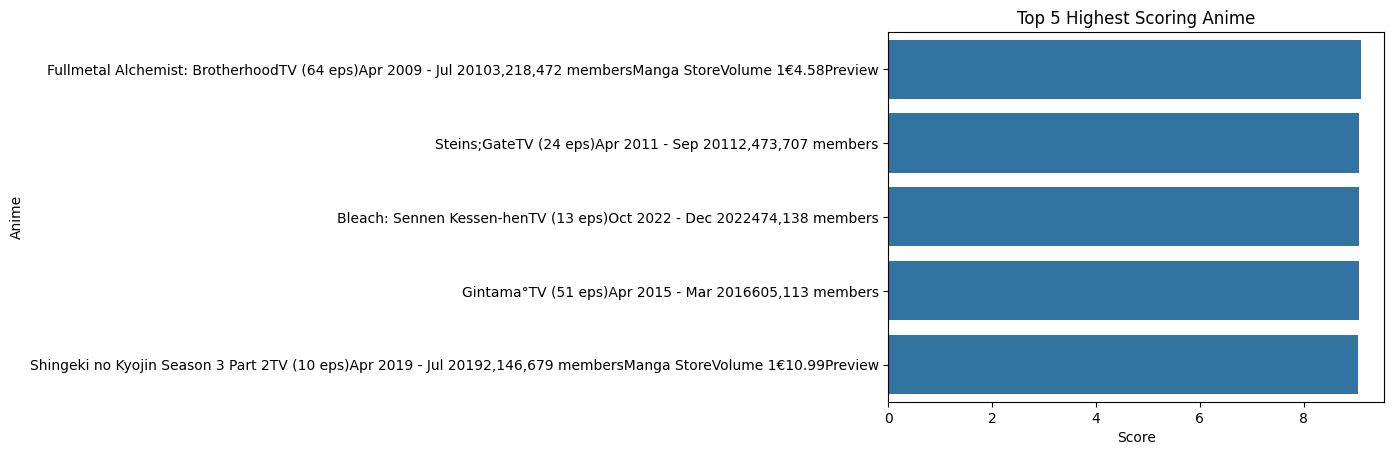

In [23]:
import matplotlib.pyplot as plt
import seaborn as sns

top5 = df.sort_values(by="Score", ascending=False).head(5)

sns.barplot(data=top5, x="Score", y="Title")

plt.title("Top 5 Highest Scoring Anime")
plt.xlabel("Score")
plt.ylabel("Anime")
plt.show()